# Sparse wafer-map metrology, part 5: the whole picture
Parts 1 to 4 each answered one question, each with the model and the rules it had at the time. Before
any of it ran, the project plan laid out **one table of runs**: every method, on every kind of site
layout. It also sketched the curves it expected to see. This notebook fills every box of that table
and draws those curves from a single run, with:

- **one model:** part 3's final model, chosen afresh on each fold's training lots;
- **one input policy:** part 4's. A reading the check questions is re-measured and kept, unless it is
  one of the two suspect readings, which are dropped;
- **one score:** the error of the delivered 89-site map (section 2).

Every number comes from holding out each lot in turn (leave-one-lot-out). Nothing new is tuned here,
and nothing is ever tuned on a test lot. These are the reference numbers for comparing methods and
sites; section 8 says why earlier notebooks show different numbers for the same box.

What it shows:
1. **The table of runs, filled in** (section 4): how much history helps, where to measure, and
   whether the gain comes from the patterns or from the sites.
2. **The three readings, expected against what happened** (section 5).
3. **The whole project, one idea per step** (section 6).
4. **The answers on one page** (section 7).

**To run:** in Colab, Runtime → Run all. The data loads from this repository's `data/` folder (or
straight from GitHub). Runs in about 2 minutes.

Data: Langer et al., BOSCH plasma-etching dataset, Zenodo 2025, doi:10.5281/zenodo.17122442 (CC BY 4.0).

## 0. Setup: data, the bad-reading screen and the random layouts
Copied unchanged from notebook 04 so that this notebook runs on its own.

In [1]:
# Tools: numpy for arrays, pandas for tables, matplotlib for plots
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Where the data files are: the repository's data/ folder, or GitHub itself (e.g. in Colab)
DATA_URL = 'https://raw.githubusercontent.com/arifulRPI/sparse-wafer-metrology/main/data/'
def data_path(name):
    for folder in ['data', '../data', '.']:
        if os.path.exists(os.path.join(folder, name)):
            return os.path.join(folder, name)
    return DATA_URL + name

# Where figures go: the repository's figures/ folder if we're inside it, else the current folder
FIG_DIR = next((d for d in ['figures', '../figures'] if os.path.isdir(d)), '.')

full = pd.read_csv(data_path('Si_Oxide_etch_89_points.csv'))  # 89 sites per wafer (Feb 2025, KLA Tencor P-17)
rout = pd.read_csv(data_path('Si_Oxide_etch_9_points.csv'))   # 9 routine sites per wafer (etch day, Veeco Dektak 8)
TARGET = 'stepheight'      # main target; silicon etch depth is repeated in section 8

In [2]:
# The wafer x site tables: one row per wafer, one column per site
full['site'] = list(zip(full.X // 1000, full.Y // 1000))          # site = (x, y) in mm
sites = sorted(full.site.unique(), key=lambda s: (-s[1], s[0]))    # fixed order: top row first
wafers = full[['experiment_key', 'lot_number', 'wafer_number']].drop_duplicates()
wafers = wafers.sort_values(['lot_number', 'wafer_number']).reset_index(drop=True)
def table(column):
    """88 x 89 array of one measured quantity (µm), rows in lot/wafer order."""
    T = full.pivot(index='experiment_key', columns='site', values=column)
    return T.loc[wafers.experiment_key, sites].to_numpy()
Y = table(TARGET)                                                  # step height
Ysi = table('si_etch')                                             # silicon etch depth (step height minus oxide)
lot = wafers.lot_number.to_numpy()
lots = np.unique(lot)
xy = np.array(sites, dtype=float)                                  # site coordinates (mm)
r = np.hypot(xy[:, 0], xy[:, 1])                                   # site radius (mm)
inner = r <= 76.5                                                  # 49 inner sites, 40 outer
r9 = rout[['loc_id', 'X', 'Y']].drop_duplicates()
routine = [sites.index((x // 1000, y // 1000)) for x, y in zip(r9.X, r9.Y)]   # the routine 9 on the grid
rout = rout.dropna(subset=['experiment_key'])                      # drop rows with no wafer label
print('table:', Y.shape, '| inner/outer sites:', inner.sum(), (~inner).sum(), '| routine sites:', len(routine))

table: (88, 89) | inner/outer sites: 49 40 | routine sites: 9


In [3]:
# The bad-reading screen (part 1, section 3): compare each reading with the median of its
# neighbours, after removing the wafer's level and the typical map. Used on training wafers only.
dist = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])  # site-to-site distances (mm)
nbrs = [np.where((dist[s] > 0) & (dist[s] < 28.5))[0] for s in range(89)]      # touching sites
same_ring = [np.argsort(np.where((np.abs(r - r[s]) <= 10) & (dist[s] > 0), dist[s], np.inf))[:2]
             for s in range(89)]                                                # replacement sites

def screen_scores(M, ref):
    """Score every reading in M; 'typical' is learned from the reference maps ref (training wafers)."""
    typical = np.median(ref - np.median(ref, axis=1, keepdims=True), axis=0)   # typical map shape
    def gap(A):
        dev = A - np.median(A, axis=1, keepdims=True) - typical                # each wafer's own deviation
        return np.stack([dev[:, s] - np.median(dev[:, nbrs[s]], axis=1) for s in range(89)], axis=1)
    g, g_ref = gap(M), gap(ref)
    centre = np.median(g_ref, axis=0)                                  # usual gap at each site
    spread = 1.4826 * np.median(np.abs(g_ref - centre), axis=0)        # MAD, scaled to match a std
    return (g - centre) / spread, g - centre                           # score, and size in µm

def screen(M, ref, threshold):
    """Flag and replace readings one at a time, worst first, until none exceed the threshold."""
    M = M.copy()
    flagged = []
    done = np.zeros(M.shape, bool)
    while True:
        z, size = screen_scores(M, ref)
        z[done] = 0                                                    # each reading is flagged at most once
        w, s = np.unravel_index(np.argmax(np.abs(z)), z.shape)        # the most unusual reading left
        if abs(z[w, s]) <= threshold:
            return M, flagged
        flagged.append((w, s, M[w, s], z[w, s], size[w, s]))
        M[w, s] = M[w, same_ring[s]].mean()                          # replace with two same-ring sites
        done[w, s] = True

THRESHOLD = 30
def suspects_of(M):
    """Where the screen flags a reading on all wafers: used only to decide what to score, never to fit."""
    return [(w, s) for w, s, *_ in screen(M, M, THRESHOLD)[1]]
suspect = suspects_of(Y)
for w, s in suspect:
    print('suspect reading: lot %d wafer %d, site %s' % (lot[w], wafers.wafer_number[w], sites[s]))

suspect reading: lot 6 wafer 7, site (-76, -38)
suspect reading: lot 3 wafer 2, site (95, -19)


In [4]:
# Which sites can be scored: False at the suspect readings (scores B and C)
def valid_mask(suspects, shape=Y.shape):
    v = np.ones(shape, bool)
    for w, s in suspects:
        v[w, s] = False
    return v
valid = valid_mask(suspect)

In [5]:
# The same random layouts as parts 1 and 2 (same seed, same order), plus 20-site layouts for the check
ks = list(range(3, 14))
rng = np.random.default_rng(0)
layouts = {k: [rng.choice(89, k, replace=False) for _ in range(200)] for k in ks}
layouts['routine 9'] = [np.array(routine)]
rng20 = np.random.default_rng(1)
layouts[20] = [rng20.choice(89, 20, replace=False) for _ in range(200)]
rng_extra = np.random.default_rng(2)                               # other sizes, used only on the inner split
for k in [2] + list(range(14, 20)):
    layouts[k] = [rng_extra.choice(89, k, replace=False) for _ in range(40)]
pos = wafers.wafer_number.to_numpy().astype(float)                 # position of each wafer in its lot (1-10)

## 1. The model, the plan and the rivals
Copied unchanged from notebook 04 (the model, the site choice and the plan; notebook 03 explains each
piece) and from notebook 02 (the rivals). The methods, in order of how much history they use:

| Method | What it does | History it uses |
|---|---|---|
| Rival B1 | a gently curved surface (level, two tilts, a bowl) through the wafer's readings | none, beyond one stiffness setting |
| Rival B2 | a Gaussian process: a smooth surface through the readings | one setting: how smooth, learned from past maps |
| Rival A | the average past map, shifted up or down to match the readings | the typical map |
| Rival A+GP | rival A, plus a Gaussian process on what it leaves | the typical map and a smoothness |
| My model | the average map plus 5 patterns learned from past maps, with a prior on their amounts | the typical map and how wafers vary |

In [6]:
SQ = dist ** 2

def leftover_corr(U):
    """How much neighbouring sites share their leftover (notebook 03, section 1)."""
    best = None
    for ell in [10, 15, 20, 25, 30, 40, 50]:
        E = np.exp(-SQ / (2 * ell ** 2))
        for nug in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7]:
            R = (1 - nug) * E + nug * np.eye(89)
            ll = -0.5 * (len(U) * np.linalg.slogdet(R)[1] + np.einsum('wi,ij,wj->', U, np.linalg.inv(R), U))
            if best is None or ll > best[0]:
                best = (ll, R)
    return best[1]

def coefficients(M, m):
    """Each wafer's level and shape amounts, by least squares on all 89 sites."""
    level = M.mean(axis=1)
    return np.column_stack([level, (M - level[:, None] - m['avg']) @ m['shapes'].T])

def learn_model(M, posM, cfg):
    """Learn a model version cfg from training maps M (rows = wafers) at positions posM."""
    K = cfg['K']
    level = M.mean(axis=1)
    dev = M - level[:, None]
    avg = dev.mean(axis=0)                                         # average map
    D = dev - avg
    shapes = np.linalg.svd(D, full_matrices=False)[2][:K]          # the K shapes (PCA)
    m = dict(cfg=cfg, avg=avg, shapes=shapes, X=np.column_stack([np.ones(89), shapes.T]))
    c = coefficients(M, m)
    if cfg['position']:
        P = np.column_stack([np.ones(len(M)), posM])
        m['B'] = np.linalg.lstsq(P, c, rcond=None)[0]
        dc, dof = c - P @ m['B'], 2
    else:
        m['B'] = c.mean(axis=0)[None, :]
        dc, dof = c - m['B'], 1
    C0 = dc.T @ dc / (len(M) - dof)                                # prior covariance of level and amounts
    m['C0'] = C0 if cfg['prior'] == 'full' else np.diag(np.diag(C0))
    leftover = D - (D @ shapes.T) @ shapes
    m['s'] = np.sqrt(np.mean(leftover ** 2, axis=0))               # leftover spread at each site
    m['R'] = leftover_corr(leftover / m['s']) if cfg['leftover'] == 'correlated' else np.eye(89)
    m['S'] = m['X'] @ m['C0'] @ m['X'].T + m['s'][:, None] * m['R'] * m['s'][None, :]
    return m

def prior_mean(m, posw):
    if m['cfg']['position']:
        return np.column_stack([np.ones(len(posw)), posw]) @ m['B']
    return np.repeat(m['B'], len(posw), axis=0)

def predict(m, idx, yk, posw):
    """Predicted full maps from readings yk at sites idx, and the spread (SD) at each site."""
    mu = m['avg'][None, :] + prior_mean(m, posw) @ m['X'].T
    S = m['S']
    if len(idx) == 0:
        return mu, np.sqrt(np.diag(S))
    A = np.linalg.solve(S[np.ix_(idx, idx)], S[idx, :])
    pred = mu + (yk - mu[:, idx]) @ A
    sd = np.sqrt(np.maximum(np.diag(S) - np.sum(S[idx, :] * A, axis=0), 0))
    return pred, sd

def surprise(m, idx, yk, posw):
    """Leave-one-out z of each reading, and the wafer's surprise d2 (notebook 03, section 1)."""
    mu = m['avg'][None, :] + prior_mean(m, posw) @ m['X'].T
    r = yk - mu[:, idx]
    P = np.linalg.inv(m['S'][np.ix_(idx, idx)])
    Pr = r @ P
    return np.abs(Pr) / np.sqrt(np.diag(P)), np.sum(Pr * r, axis=1)

In [7]:
CFGS = [dict(K=k, prior=p, position=q, leftover=l) for l in ['independent', 'correlated']
        for p in ['diag', 'full'] for q in [False, True] for k in [3, 4, 5]]
def cfg_name(c):
    return '%d shapes, %s prior%s%s' % (c['K'], c['prior'], ', position' if c['position'] else '',
                                       ', correlated leftover' if c['leftover'] == 'correlated' else '')
def additions(c):
    return (c['prior'] == 'full') + c['position'] + (c['leftover'] == 'correlated')
LAY4 = [3, 5, 9, 'routine 9']
CHECK_RATE, FLAG_RATE = 0.01, 0.05
KS_CHECK = list(range(2, 21))

def inner_layouts(k, n=40):
    return layouts[k] if k == 'routine 9' else layouts[k][:n]

def choose_model(M, G, pM, versions=CFGS, n=40):
    """Score each version on the inner split (hide one group of G at a time); simplest within 1% of the best."""
    scores = []
    for cfg in versions:
        sse = {lay: np.zeros(2) for lay in LAY4}
        for g in np.unique(G):
            o = G != g
            mo = learn_model(M[o], pM[o], cfg)
            for lay in LAY4:
                for idx in inner_layouts(lay, n):
                    p = predict(mo, idx, M[~o][:, idx], pM[~o])[0]
                    hid = np.ones(89, bool); hid[idx] = False
                    sse[lay] += [((p - M[~o])[:, hid] ** 2).sum(), (~o).sum() * hid.sum()]
        scores.append(np.exp(np.mean([np.log(np.sqrt(a[0] / a[1])) for a in sse.values()])))
    scores = np.array(scores)
    near = np.where(scores <= 1.01 * scores.min())[0]
    return versions[min(near, key=lambda i: (additions(versions[i]), versions[i]['K'], scores[i]))]

def inner_split(M, G, pM, cfg, n=40, thresholds=True):
    """Hide one group at a time: standardized misses (range factor), largest leave-one-out z (check
    threshold) and d2 (flag threshold) on the hidden group's clean maps."""
    misses, zmax, d2 = [], {k: [] for k in KS_CHECK}, {k: [] for k in KS_CHECK}
    for g in np.unique(G):
        o = G != g
        mo = learn_model(M[o], pM[o], cfg)
        Mt, pt = M[~o], pM[~o]
        for k in LAY4:
            for idx in inner_layouts(k, n):
                p, sd = predict(mo, idx, Mt[:, idx], pt)
                hid = np.ones(89, bool); hid[idx] = False
                misses.append((len(idx), np.abs(p - Mt)[:, hid] / sd[hid], surprise(mo, idx, Mt[:, idx], pt)[1]))
        if thresholds:
            for k in KS_CHECK:
                for idx in inner_layouts(k, n):
                    z, dd = surprise(mo, idx, Mt[:, idx], pt)
                    zmax[k] += list(z.max(axis=1))
                    d2[k] += list(dd)
    return misses, zmax, d2

def widening(misses, keep=None):
    """The factor that puts 90% of the standardized misses inside the range."""
    z = np.concatenate([zz[keep(k, dd)] if keep else zz for k, zz, dd in misses], axis=None)
    return np.quantile(z, 0.90) / 1.645

def map_error(m, idx):
    """The model's predicted error of the map (pattern part), summed over the 89 sites, after measuring idx."""
    X, w = m['X'], 1 / m['s'][idx] ** 2
    cov = np.linalg.inv(np.linalg.inv(m['C0']) + X[idx].T @ (w[:, None] * X[idx]))
    return np.sum((X @ cov) * X)

def choose_sites(m, n):
    """Add sites one at a time, each time the one that most lowers the predicted map error."""
    chosen = []
    for _ in range(n):
        err = [map_error(m, chosen + [s]) if s not in chosen else np.inf for s in range(89)]
        chosen.append(int(np.argmin(err)))
    return np.array(chosen)

In [8]:
def plan_size(M, G, pM, cfg, kmax=13):
    """On the inner split: squared error of chosen layouts (3 to kmax sites, chosen without the hidden
    group) and of the routine 9, on the sites both leave unmeasured. Returns the fewest sites that do no
    worse than the routine 9, and the inner-split errors."""
    sse = {k: np.zeros(4) for k in range(3, kmax + 1)}            # chosen sse, routine sse, count, -
    for g in np.unique(G):
        o = G != g
        mo = learn_model(M[o], pM[o], cfg)
        so = choose_sites(mo, kmax)
        Mt, pt = M[~o], pM[~o]
        e_r = (predict(mo, np.array(routine), Mt[:, routine], pt)[0] - Mt) ** 2
        for k in range(3, kmax + 1):
            idx = so[:k]
            e_c = (predict(mo, idx, Mt[:, idx], pt)[0] - Mt) ** 2
            both = np.ones(89, bool); both[idx] = False; both[routine] = False
            sse[k] += [e_c[:, both].sum(), e_r[:, both].sum(), len(Mt) * both.sum(), 0]
    ratio = {k: a[0] / a[1] for k, a in sse.items()}
    ok = [k for k in ratio if ratio[k] <= 1]
    return (min(ok) if ok else kmax), ratio

In [9]:
def learn_plan(Ytr, G, pM, versions=CFGS, n=40, kmax=13):
    cfg = choose_model(Ytr, G, pM, versions, n)
    P = dict(cfg=cfg, m=learn_model(Ytr, pM, cfg))
    misses, zmax, d2 = inner_split(Ytr, G, pM, cfg, n)
    P['T'] = {k: np.quantile(v, 1 - CHECK_RATE) for k, v in zmax.items()}
    P['TF'] = {k: np.quantile(v, 1 - FLAG_RATE) for k, v in d2.items()}
    P['f'] = widening(misses, keep=lambda k, dd: dd <= P['TF'][k])
    P['sites'] = choose_sites(P['m'], 20)
    P['k_rule'], P['ratio'] = plan_size(Ytr, G, pM, cfg, kmax)
    P['k'] = max(P['k_rule'], cfg['K'])                                # at least one reading per shape
    return P

def training_set(train_lots):
    """Screened maps, lot labels and positions of the training wafers."""
    tr = np.isin(lot, train_lots)
    Ytr, _ = screen(Y[tr], Y[tr], THRESHOLD)
    return Ytr, lot[tr], pos[tr]

def apply_plan(P, L, layouts_to_test):
    """Measure every wafer of lot L at each layout; returns one record per wafer and layout."""
    te = np.where(lot == L)[0]
    recs = []
    for name, idx in layouts_to_test:
        yk = Y[te][:, idx]
        z = surprise(P['m'], idx, yk, pos[te])[0]
        for i, w in enumerate(te):
            keep = np.ones(len(idx), bool)
            j = z[i].argmax()
            remeasured = z[i, j] > P['T'][len(idx)]
            if remeasured and (w, idx[j]) in suspect:                  # the repeat disagrees: drop it
                keep[j] = False
            sel, y = idx[keep], yk[[i]][:, keep]
            p, sd = predict(P['m'], sel, y, pos[[w]])
            flagged = surprise(P['m'], sel, y, pos[[w]])[1][0] > P['TF'][len(sel)]
            hid = np.ones(89, bool); hid[idx] = False
            h = hid & valid[w]                                        # score C: suspect sites never scored
            e2 = np.where(h, (p[0] - Y[w]) ** 2, np.nan)
            inside = np.where(h, np.abs(p[0] - Y[w]) <= 1.645 * P['f'] * sd, np.nan)
            recs.append(dict(lot=L, row=w, wafer=int(wafers.wafer_number[w]), layout=name, k=len(idx),
                             remeasured=int(remeasured), flagged=int(flagged), e2=e2, inside=inside))
    return recs

In [10]:
def rms_of(D, region=None):
    """RMS error over the scored hidden sites of the records in D (region: inner, edge or None)."""
    if len(D) == 0:
        return np.nan
    E = np.stack(D.e2.to_numpy())
    if region is not None:
        E = E[:, region]
    return np.sqrt(np.nanmean(E))

def coverage_of(D):
    if len(D) == 0:
        return np.nan
    return np.nanmean(np.stack(D.inside.to_numpy()))

def map_rms(D, full_if_flagged=True):
    """Error of the delivered 89-site map: measured sites count as exact, a flagged wafer is measured in full."""
    E = np.nan_to_num(np.stack(D.e2.to_numpy()))
    if full_if_flagged:
        E = np.where(D.flagged.to_numpy()[:, None] == 1, 0.0, E)
    return np.sqrt(E.mean())

In [11]:
# The rivals, copied from notebook 02 (section 2)
xs, ys = xy[:, 0] / 100.0, xy[:, 1] / 100.0
PHI = np.column_stack([np.ones(89), xs, ys, xs**2 + ys**2])        # rival B1: level, two tilts, a bowl
LAMS = [1e-3, 1e-2, 1e-1, 1, 10, 100]

def poly_fit(idx, yk, lam):
    P = PHI[idx]
    c = np.linalg.solve(P.T @ P + lam * np.diag([0, 1, 1, 1.0]), P.T @ yk.T)
    return (PHI @ c).T

def choose_lam(Ytr, lays):
    """Ridge strength for rival B1, chosen on training wafers with the same kind of layout."""
    sse = []
    for lam in LAMS:
        e = 0
        for idx in lays:
            h = np.ones(89, bool); h[idx] = False
            e += ((poly_fit(idx, Ytr[:, idx], lam) - Ytr)[:, h] ** 2).sum()
        sse.append(e)
    return LAMS[int(np.argmin(sse))]

D2 = dist ** 2
def gp_learn(Ytr):
    """Rival B2: smoothness (length scale) and noise share by maximum likelihood on training full maps."""
    Z = Ytr - Ytr.mean(axis=1, keepdims=True)
    N, best = len(Z), None
    for ell in [20, 30, 40, 60, 80, 100, 130, 160, 200, 260]:
        Rm = np.exp(-D2 / (2 * ell ** 2))
        for ratio in [0.01, 0.03, 0.1, 0.3]:
            C = Rm + ratio ** 2 * np.eye(89)
            s2 = np.einsum('wi,ij,wj->', Z, np.linalg.inv(C), Z) / (N * 89)
            ll = -0.5 * (N * 89 * np.log(s2) + N * np.linalg.slogdet(C)[1])
            if best is None or ll > best[0]:
                best = (ll, ell, ratio)
    return dict(ell=best[1], ratio=best[2])

def gp_fit(g, idx, yk):
    """Gaussian-process interpolation of readings yk at sites idx, around a constant level."""
    Rm = np.exp(-D2 / (2 * g['ell'] ** 2))
    Ci = np.linalg.inv(Rm[np.ix_(idx, idx)] + g['ratio'] ** 2 * np.eye(len(idx)))
    one = np.ones(len(idx))
    mu = (yk @ Ci @ one) / (one @ Ci @ one)
    return mu[:, None] + (Rm[:, idx] @ Ci @ (yk - mu[:, None]).T).T

def gpa_learn(Ytr, avg):
    """Rival A+GP: the average map, plus a Gaussian process on each wafer's deviation from it."""
    return gp_learn(Ytr - Ytr.mean(axis=1, keepdims=True) - avg) | {'avg': avg}

def gpa_fit(g, idx, yk):
    return g['avg'][None, :] + gp_fit(g, idx, yk - g['avg'][idx][None, :])

def gp_sites(g, n):
    """A Gaussian process's own best sites: add, one at a time, the site that most lowers its summed variance."""
    Rm = np.exp(-D2 / (2 * g['ell'] ** 2))
    chosen = []
    for _ in range(n):
        v = [np.inf] * 89
        for s in range(89):
            if s not in chosen:
                idx = chosen + [s]
                C = Rm[np.ix_(idx, idx)] + g['ratio'] ** 2 * np.eye(len(idx))
                v[s] = np.sum(np.diag(Rm) - np.sum(Rm[idx, :] * np.linalg.solve(C, Rm[idx, :]), axis=0))
        chosen.append(int(np.argmin(v)))
    return np.array(chosen)

Two additions. **Each method's own best sites** use the same greedy rule for every method: add, one at
a time, the site that most lowers the method's own predicted error over the 89 sites. For my model and
rival A that is `choose_sites` (section 1); for the Gaussian processes, `gp_sites` (notebook 04); for
rival B1, `poly_sites` below. **The second instrument** read the routine 9 on etch day (notebook 02,
section 7). Its offset and scatter are learned from training lots only. Every method gets the readings
with the offset removed; my model and rival A also add the scatter to the noise of each reading.

In [12]:
def poly_sites(n):
    """Rival B1's own best sites: add, one at a time, the site that most lowers the summed prediction
    variance of its surface."""
    D = np.diag([0, 1, 1, 1.0])
    chosen = []
    for _ in range(n):
        v = [np.inf] * 89
        for s in range(89):
            if s not in chosen:
                P = PHI[chosen + [s]]
                v[s] = np.sum((PHI @ np.linalg.inv(P.T @ P + 1e-3 * D)) * PHI)
        chosen.append(int(np.argmin(v)))
    return np.array(chosen)

def predict_noisy(m, idx, yk, posw, extra):
    """The model's prediction when every reading carries an extra instrument scatter of variance `extra`."""
    mu = m['avg'][None, :] + prior_mean(m, posw) @ m['X'].T
    S = m['S']
    A = np.linalg.solve(S[np.ix_(idx, idx)] + extra * np.eye(len(idx)), S[idx, :])
    return mu + (yk - mu[:, idx]) @ A

# The second instrument's routine readings, arranged like the map table (its sites are turned 180°)
row_of = {k: i for i, k in enumerate(wafers.experiment_key)}
real = np.full((88, 9), np.nan)
for _, rec in rout[rout.experiment_key.isin(set(wafers.experiment_key))].iterrows():
    j = sites.index((-rec.X // 1000, -rec.Y // 1000))
    real[row_of[rec.experiment_key], routine.index(j)] = rec[TARGET]
has = ~np.isnan(real).any(axis=1)
print('second instrument: %d wafers with a full map, lots %s' % (has.sum(), sorted(set(lot[has].tolist()))))

second instrument: 73 wafers with a full map, lots [1, 2, 3, 4, 5, 6, 7, 9]


## 2. One score: the error of the delivered map
The map a fab actually gets holds the **readings where the wafer was measured and the predictions
everywhere else**. Every box is scored on that map, against the measured full map: the RMS error over
all 89 sites, and separately over the inner 49 and the edge 40. A measured site has no error (unless a
second instrument read it). The two suspect readings are never scored. Why this score:

1. **It compares layouts fairly.** Scoring only the unmeasured sites favours a layout that measures the
   hard sites, because it then hides only easy ones. My model's chosen sites sit mostly at the edge,
   where errors are largest. Part 4 got around this by scoring only the sites both layouts leave
   unmeasured; the delivered map does the same job for any number of layouts at once.
2. **It is what the fab gets.**
3. **Part 4's plan and budget already use it**, so the numbers line up.

**The floor.** Each test wafer's level and pattern amounts are also read off its own full map (least
squares), as if they were known exactly. The map this gives, with measured sites still exact, is the
best my model's average map and patterns can describe that wafer. Whatever is left is detail the
patterns do not hold, and only measuring a site removes it there.

In [13]:
def map_sse(pred, te, idx, readings=None):
    """Squared error and number of scored sites of the delivered maps of wafers te measured at sites idx,
    inner then edge. Delivered map: readings where measured, pred(sel, y, w) everywhere else. A suspect
    reading among the inputs is dropped, as the check and a re-measurement would do. `readings`: another
    instrument's readings at idx, one row per wafer (default: read the map)."""
    out = np.zeros(4)
    idx = np.asarray(idx)
    if readings is None:
        clean = valid[te][:, idx].all(axis=1)
        groups = [(te[clean], idx)] + [(te[[i]], idx[valid[te[i], idx]]) for i in np.where(~clean)[0]]
    else:
        groups = [(te, idx)]
    for w, sel in groups:
        if len(w) == 0:
            continue
        y = Y[w][:, sel] if readings is None else readings[w]
        D = pred(sel, y, w).copy()
        D[:, sel] = y                                                  # readings where measured
        e2 = np.where(valid[w], (D - Y[w]) ** 2, 0)
        out += [e2[:, inner].sum(), valid[w][:, inner].sum(), e2[:, ~inner].sum(), valid[w][:, ~inner].sum()]
    return out

## 3. The run: every box of the table
For each held-out lot, everything is learned from the other nine: the plan (model version, thresholds,
chosen sites and how many), rival A, the Gaussian processes' settings, and rival B1's stiffness for each
kind of layout. Then every wafer of the held-out lot is measured, in turn:

- at **random sites**: the same 200 layouts per count from 3 to 13 (part 1's layouts, drawn once and
  reused on every lot), by every method;
- at **my model's chosen sites**: 1 to 20 sites for my model, 3 to 13 for the rivals;
- at **each method's own best sites**, 3 to 13;
- at **the routine 9**, read off the maps, and as read by the second instrument (73 wafers in 8 lots);
- and for **the floor**, and **the plan as deployed** (part 4: check, re-measure, flag → full map).

In [14]:
METHODS = ['B1', 'B2', 'A', 'A+GP', 'ours']
A0 = dict(K=0, prior='diag', position=False, leftover='independent')    # rival A: level only
KR, KC = list(range(3, 14)), list(range(1, 21))
NR = 200
RES, INFO, PLAN_RECS = {}, {}, []
def put(key, j, li, a, n_layouts=1):
    """Add squared errors a for layout j of test lot li to box `key`."""
    if key not in RES:
        RES[key] = np.zeros((n_layouts, len(lots), 4))
    RES[key][j, li] += a

t0 = time.time()
for li, L in enumerate(lots):
    Ytr, ltr, ptr = training_set(lots[lots != L])
    te = np.where(lot == L)[0]
    P = learn_plan(Ytr, ltr, ptr)
    m, mA = P['m'], learn_model(Ytr, ptr, A0)
    gB2, gAGP = gp_learn(Ytr), gpa_learn(Ytr, mA['avg'])
    fn = {'ours': lambda sel, y, w: predict(m, sel, y, pos[w])[0],
          'A': lambda sel, y, w: predict(mA, sel, y, pos[w])[0],
          'A+GP': lambda sel, y, w: gpa_fit(gAGP, sel, y),
          'B2': lambda sel, y, w: gp_fit(gB2, sel, y)}
    b1 = lambda lam: (lambda sel, y, w: poly_fit(sel, y, lam))
    own = {'ours': P['sites'], 'A': choose_sites(mA, 13), 'A+GP': gp_sites(gAGP, 13),
           'B2': gp_sites(gB2, 13), 'B1': poly_sites(13)}
    INFO[L] = dict(cfg=P['cfg'], k=P['k'], k_rule=P['k_rule'], own=own)
    # random sites: every method, the same layouts on every test lot
    for k in KR:
        f_all = dict(fn, B1=b1(choose_lam(Ytr, layouts[k][:40])))
        for j, idx in enumerate(layouts[k][:NR]):
            for meth in METHODS:
                put(('random', k, meth), j, li, map_sse(f_all[meth], te, idx), NR)
    # my model's chosen sites, for every method; each method's own best sites
    for k in KC:
        put(('chosen', k, 'ours'), 0, li, map_sse(fn['ours'], te, P['sites'][:k]))
    for k in KR:
        for kind, sets in [('chosen', {meth: P['sites'] for meth in METHODS}), ('own', own)]:
            for meth in METHODS:
                if kind == 'chosen' and meth == 'ours':
                    continue
                idx = sets[meth][:k]
                f = b1(choose_lam(Ytr, [idx])) if meth == 'B1' else fn[meth]
                put((kind, k, meth), 0, li, map_sse(f, te, idx))
    # the routine 9 read off the maps: all wafers, and the wafers the second instrument measured
    R9 = np.array(routine)
    f_all = dict(fn, B1=b1(choose_lam(Ytr, [R9])))
    ti = te[has[te]]
    for meth in METHODS:
        put(('routine', 9, meth), 0, li, map_sse(f_all[meth], te, R9))
        if len(ti):
            put(('routine, same wafers', 9, meth), 0, li, map_sse(f_all[meth], ti, R9))
    # the routine 9 read by the second instrument: offset and scatter from training lots only
    if len(ti):
        tr = has & (lot != L)
        diff = real[tr] - Y[tr][:, routine]
        offset, extra = diff.mean(), diff.var()
        rd = np.full((88, 9), np.nan)
        rd[ti] = real[ti] - offset
        f_inst = dict(f_all, ours=lambda sel, y, w: predict_noisy(m, sel, y, pos[w], extra),
                      A=lambda sel, y, w: predict_noisy(mA, sel, y, pos[w], extra))
        for meth in METHODS:
            put(('instrument', 9, meth), 0, li, map_sse(f_inst[meth], ti, R9, readings=rd))
        INFO[L].update(offset=offset, scatter=np.sqrt(extra))
    # the floor: level and pattern amounts read off the full map, the chosen sites still exact
    for k in KC:
        hid = np.ones(89, bool)
        hid[P['sites'][:k]] = False
        a = np.zeros(4)
        for w in te:
            v = valid[w]
            c = np.linalg.lstsq(m['X'][v], (Y[w] - m['avg'])[v], rcond=None)[0]
            e2 = np.where(v & hid, (m['avg'] + m['X'] @ c - Y[w]) ** 2, 0)
            a += [e2[inner].sum(), (v & inner).sum(), e2[~inner].sum(), (v & ~inner).sum()]
        put(('floor', k, 'ours'), 0, li, a)
    # the plan as deployed (notebook 04): check, re-measure, flag -> full map
    PLAN_RECS += apply_plan(P, L, [('plan', P['sites'][:P['k']]), ('chosen 5', P['sites'][:5])])
    print('test lot %2d: %-32s | plan %d sites | %.0f s' % (L, cfg_name(P['cfg']), P['k'], time.time() - t0))
PLAN = pd.DataFrame(PLAN_RECS)

test lot  1: 5 shapes, full prior             | plan 5 sites | 6 s


test lot  2: 5 shapes, full prior             | plan 5 sites | 12 s


test lot  3: 5 shapes, full prior             | plan 5 sites | 19 s


test lot  4: 5 shapes, full prior             | plan 6 sites | 25 s


test lot  5: 5 shapes, full prior             | plan 5 sites | 31 s


test lot  6: 5 shapes, full prior             | plan 5 sites | 37 s


test lot  7: 5 shapes, full prior             | plan 5 sites | 43 s


test lot  8: 4 shapes, full prior, position   | plan 5 sites | 50 s


test lot  9: 5 shapes, full prior             | plan 5 sites | 56 s


test lot 10: 5 shapes, full prior             | plan 5 sites | 63 s


## 4. The table of runs, filled in
The headline counts are those the October plan chose: 5 sites, and the routine 9. Every count from 3 to
13 follows, and the curves in section 5 show them all. In 9 folds of 10 the inner split picks part 3's
final model (5 patterns, joint prior); in the fold without lot 8 it picks 4 patterns with position.

In [15]:
def err(key, part=None, layout=None):
    """RMS error of the delivered maps in box `key`, over all test lots (and layouts, unless one is given).
    part: None for the whole map, 'inner' or 'edge'."""
    a = RES[key] if layout is None else RES[key][layout:layout + 1]
    a = a.reshape(-1, 4).sum(axis=0)
    if part == 'inner':
        return np.sqrt(a[0] / a[1])
    if part == 'edge':
        return np.sqrt(a[2] / a[3])
    return np.sqrt((a[0] + a[2]) / (a[1] + a[3]))

def per_lot(key):
    """Whole-map RMS error of box `key`, lot by lot."""
    a = RES[key].sum(axis=0)
    with np.errstate(invalid='ignore'):                                # lots the second instrument never measured
        return np.sqrt((a[:, 0] + a[:, 2]) / (a[:, 1] + a[:, 3]))

NAME = {'B1': 'rival B1', 'B2': 'rival B2', 'A': 'rival A', 'A+GP': 'rival A+GP', 'ours': 'my model'}
ROWS = [('5 random sites', ('random', 5)), ('5 chosen sites', ('chosen', 5)), ('5 sites, each its own best', ('own', 5)),
        ('routine 9, read off the maps', ('routine', 9)), ('routine 9, same 73 wafers', ('routine, same wafers', 9)),
        ('routine 9, 2nd instrument', ('instrument', 9))]
def box(kind, k, meth):
    key = ('chosen', k, 'ours') if (kind, meth) == ('own', 'ours') else (kind, k, meth)
    f = '%.2f' if err(key) >= 1 else '%.3f'
    return (f + ' (' + f + ' / ' + f + ')') % (err(key), err(key, 'inner'), err(key, 'edge'))
print('Error of the delivered 89-site map, µm RMS: whole map (inner / edge), every lot held out in turn\n')
print(pd.DataFrame({NAME[meth]: {row: box(*key, meth) for row, key in ROWS} for meth in METHODS}).to_string())
print('\nOffset of the second instrument %.2f µm, scatter %.3f µm (learned without the held-out lot; average over folds)'
      % (np.mean([v['offset'] for v in INFO.values() if 'offset' in v]), np.mean([v['scatter'] for v in INFO.values() if 'scatter' in v])))

Error of the delivered 89-site map, µm RMS: whole map (inner / edge), every lot held out in turn

                                        rival B1            rival B2                rival A             rival A+GP               my model
5 random sites                3.20 (1.98 / 4.24)  3.99 (3.03 / 4.91)  0.141 (0.082 / 0.189)  0.127 (0.082 / 0.167)  0.076 (0.037 / 0.105)
5 chosen sites                2.63 (1.71 / 3.43)  5.00 (3.94 / 6.04)  0.128 (0.098 / 0.157)  0.206 (0.158 / 0.253)  0.044 (0.029 / 0.058)
5 sites, each its own best    3.15 (3.30 / 2.96)  4.42 (0.66 / 6.55)  0.135 (0.092 / 0.174)  0.128 (0.037 / 0.187)  0.044 (0.029 / 0.058)
routine 9, read off the maps  3.54 (0.39 / 5.26)  3.82 (0.33 / 5.69)  0.137 (0.068 / 0.190)  0.105 (0.019 / 0.155)  0.067 (0.016 / 0.099)
routine 9, same 73 wafers     3.53 (0.39 / 5.26)  3.82 (0.32 / 5.68)  0.140 (0.071 / 0.193)  0.103 (0.018 / 0.152)  0.060 (0.016 / 0.087)
routine 9, 2nd instrument     3.55 (0.39 / 5.28)  3.82 (0.32 / 5.69)  0.14

In [16]:
print('Whole map, every count (µm):')
full_table = pd.DataFrame({('%s, %s' % (kind, NAME[meth])): {k: err((kind, k, meth) if (kind, meth) != ('own', 'ours') else ('chosen', k, 'ours'))
                                                          for k in KR}
                           for kind in ['random', 'chosen', 'own'] for meth in METHODS})
print(full_table.round(3).T.to_string())

Whole map, every count (µm):
                       3      4      5      6      7      8      9      10     11     12     13
random, rival B1    3.893  3.593  3.200  2.991  2.746  2.643  2.469  2.432  2.184  2.167  2.133
random, rival B2    4.045  3.972  3.988  3.874  4.009  3.956  3.816  3.731  3.441  3.254  3.025
random, rival A     0.146  0.145  0.141  0.139  0.137  0.136  0.134  0.134  0.131  0.130  0.130
random, rival A+GP  0.147  0.135  0.127  0.122  0.118  0.117  0.109  0.107  0.104  0.102  0.099
random, my model    0.095  0.084  0.076  0.069  0.066  0.062  0.060  0.060  0.056  0.055  0.054
chosen, rival B1    3.458  3.499  2.628  2.646  2.178  1.867  1.908  1.953  2.004  2.008  1.948
chosen, rival B2    4.598  5.140  4.995  4.660  4.831  4.529  4.070  3.737  4.088  3.570  3.229
chosen, rival A     0.132  0.129  0.128  0.127  0.124  0.122  0.122  0.121  0.119  0.117  0.115
chosen, rival A+GP  0.185  0.229  0.206  0.191  0.192  0.185  0.151  0.134  0.125  0.114  0.107
chosen, my 

In [17]:
print('Lots (of 10) where my model beats each rival, same 5 random sites:',
      {NAME[meth]: int((per_lot(('random', 5, 'ours')) < per_lot(('random', 5, meth))).sum()) for meth in METHODS[:-1]})
print('How many times worse than my model, random sites:')
for k in [3, 5, 9, 13]:
    print('  %2d sites: ' % k + '  '.join('%s ×%.1f' % (NAME[meth], err(('random', k, meth)) / err(('random', k, 'ours')))
                                         for meth in METHODS[:-1]))
pi, ok = per_lot(('instrument', 9, 'ours')), ~np.isnan(per_lot(('instrument', 9, 'ours')))
print('Second instrument, lots (of %d) where my model beats each rival:' % ok.sum(),
      {NAME[meth]: int((pi[ok] < per_lot(('instrument', 9, meth))[ok]).sum()) for meth in METHODS[:-1]})

Lots (of 10) where my model beats each rival, same 5 random sites: {'rival B1': 10, 'rival B2': 10, 'rival A': 10, 'rival A+GP': 10}
How many times worse than my model, random sites:
   3 sites: rival B1 ×41.0  rival B2 ×42.6  rival A ×1.5  rival A+GP ×1.6
   5 sites: rival B1 ×42.3  rival B2 ×52.8  rival A ×1.9  rival A+GP ×1.7
   9 sites: rival B1 ×41.4  rival B2 ×64.0  rival A ×2.3  rival A+GP ×1.8
  13 sites: rival B1 ×39.5  rival B2 ×56.1  rival A ×2.4  rival A+GP ×1.8
Second instrument, lots (of 8) where my model beats each rival: {'rival B1': 8, 'rival B2': 8, 'rival A': 8, 'rival A+GP': 7}


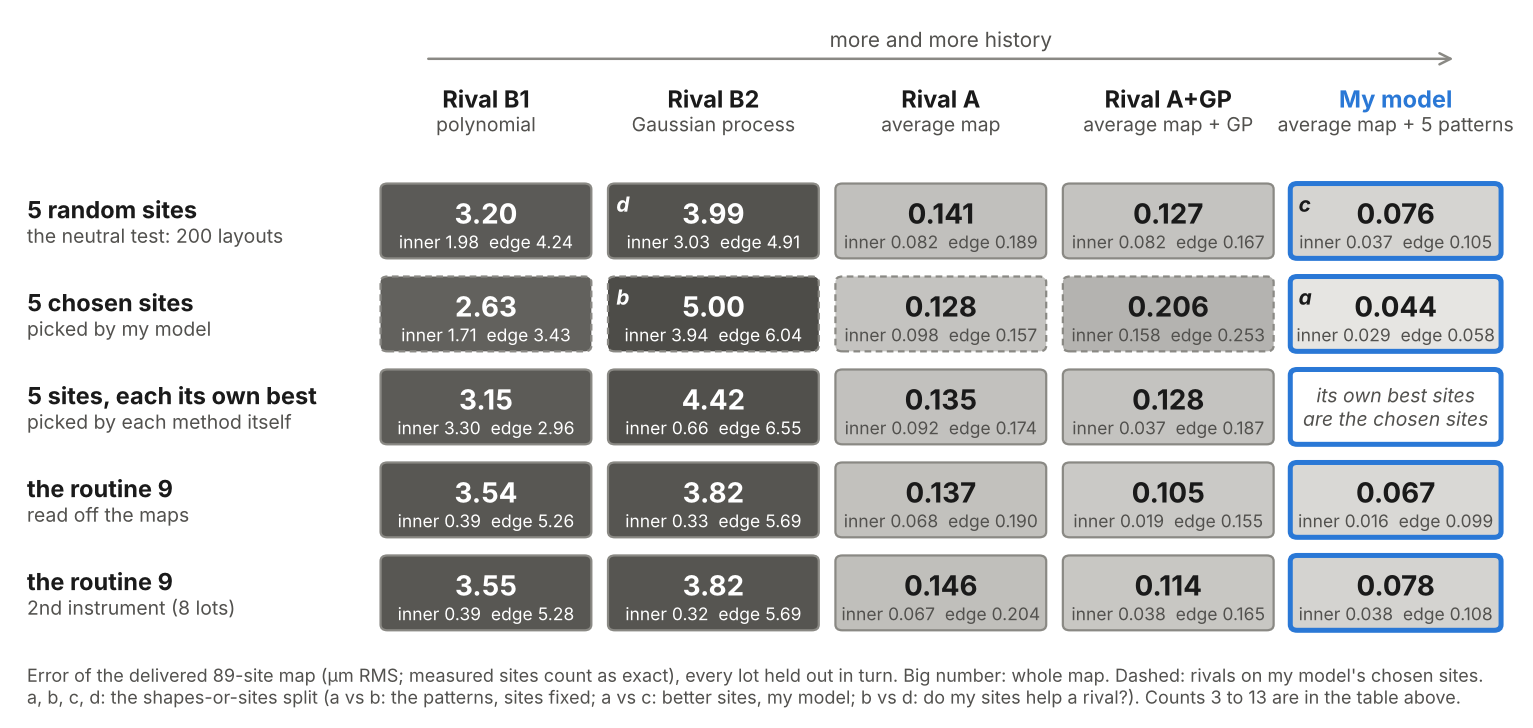

In [18]:
# Figure: the table of runs, filled in (the October plan's grid)
from matplotlib.patches import FancyBboxPatch
INK, INK2, INK3, GRID = '#1a1a1a', '#52514e', '#8a8984', '#e4e3df'
COL = {'B1': '#8a8984', 'B2': '#52514e', 'A': '#eb6834', 'A+GP': '#1baf7a', 'ours': '#2a78d6'}
FIG_ROWS = [('5 random sites', 'the neutral test: 200 layouts', 'random', 5),
            ('5 chosen sites', 'picked by my model', 'chosen', 5),
            ('5 sites, each its own best', 'picked by each method itself', 'own', 5),
            ('the routine 9', 'read off the maps', 'routine', 9),
            ('the routine 9', '2nd instrument (8 lots)', 'instrument', 9)]
FIG_COLS = [('B1', 'Rival B1', 'polynomial'), ('B2', 'Rival B2', 'Gaussian process'), ('A', 'Rival A', 'average map'),
            ('A+GP', 'Rival A+GP', 'average map + GP'), ('ours', 'My model', 'average map + 5 patterns')]
LETTER = {('chosen', 'ours'): 'a', ('chosen', 'B2'): 'b', ('random', 'ours'): 'c', ('random', 'B2'): 'd'}
def shade(v, lo=np.log10(0.03), hi=np.log10(6)):
    """A grey from light (small error) to dark (large), on a log scale; and how dark (0-1)."""
    t = np.clip((np.log10(v) - lo) / (hi - lo), 0, 1)
    c0, c1 = np.array([0xf3, 0xf2, 0xef]) / 255, np.array([0x47, 0x46, 0x42]) / 255
    return tuple(c0 + (c1 - c0) * t), t

fig, ax = plt.subplots(figsize=(9.6, 4.3))
W, H, X0, DX, DY = 1.52, 0.66, 2.55, 1.64, 0.82
for j, (meth, nm, sub) in enumerate(FIG_COLS):
    x = X0 + j * DX
    ax.text(x + W / 2, 0.62, nm, ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=COL['ours'] if meth == 'ours' else INK)
    ax.text(x + W / 2, 0.42, sub, ha='center', va='bottom', fontsize=7, color=INK2)
ax.annotate('', xy=(X0 + 4 * DX + W * 0.8, 1.1), xytext=(X0 + W * 0.2, 1.1), arrowprops=dict(arrowstyle='->', color=INK3, lw=0.9))
ax.text(X0 + 2 * DX + W / 2, 1.16, 'more and more history', ha='center', va='bottom', fontsize=7.5, color=INK2)
for i, (nm, sub, kind, k) in enumerate(FIG_ROWS):
    y = -i * DY
    ax.text(0.0, y - H / 2 + 0.1, nm, ha='left', va='center', fontsize=8.5, fontweight='bold', color=INK)
    ax.text(0.0, y - H / 2 - 0.13, sub, ha='left', va='center', fontsize=7, color=INK2)
    for j, (meth, *_) in enumerate(FIG_COLS):
        x = X0 + j * DX
        if (kind, meth) == ('own', 'ours'):                           # my model's own best sites are its chosen sites
            ax.add_patch(FancyBboxPatch((x, y - H), W, H, boxstyle='round,pad=0,rounding_size=0.05', fc='white', ec=COL['ours'], lw=1.8))
            ax.text(x + W / 2, y - H / 2, 'its own best sites\nare the chosen sites', ha='center', va='center', fontsize=7, color=INK2, style='italic')
            continue
        v, vi, ve = err((kind, k, meth)), err((kind, k, meth), 'inner'), err((kind, k, meth), 'edge')
        fc, t = shade(v)
        ax.add_patch(FancyBboxPatch((x, y - H), W, H, boxstyle='round,pad=0,rounding_size=0.05', fc=fc,
                                    ec=COL['ours'] if meth == 'ours' else INK3, lw=1.8 if meth == 'ours' else 0.8,
                                    ls=(0, (3, 2)) if kind == 'chosen' and meth != 'ours' else '-'))
        tc = 'white' if t > 0.55 else INK
        f = '%.2f' if v >= 1 else '%.3f'
        ax.text(x + W / 2, y - H * 0.40, f % v, ha='center', va='center', fontsize=10, color=tc, fontweight='bold')
        ax.text(x + W / 2, y - H * 0.78, ('inner ' + f + '  edge ' + f) % (vi, ve), ha='center', va='center', fontsize=6.3,
                color=tc if t > 0.55 else INK2)
        if (kind, meth) in LETTER:
            ax.text(x + 0.06, y - 0.07, LETTER[(kind, meth)], ha='left', va='top', fontsize=7.5, color=tc, fontweight='bold', style='italic')
ax.set_xlim(-0.05, X0 + 4 * DX + W + 0.05)
ax.set_ylim(-4 * DY - H - 0.45, 1.45)
ax.axis('off')
ax.text(0, -4 * DY - H - 0.3, 'Error of the delivered 89-site map (µm RMS; measured sites count as exact), every lot held out in turn. '
        'Big number: whole map. Dashed: rivals on my model\'s chosen sites.\na, b, c, d: the shapes-or-sites split '
        '(a vs b: the patterns, sites fixed; a vs c: better sites, my model; b vs d: do my sites help a rival?). '
        'Counts 3 to 13 are in the table above.', fontsize=6.5, color=INK2, va='top')
fig.savefig(os.path.join(FIG_DIR, 'part5_table.png'), dpi=220, bbox_inches='tight')
plt.show()

**Reading the table.**
- **Across a row: how much history helps.** On the same 5 random sites the two rivals without history
  miss by microns (3.20 and 3.99 µm), and the three with history by hundredths: rival A 0.141, rival
  A+GP 0.127, my model 0.076. My model is about 40 times better than the polynomial and 50 times better
  than the Gaussian process, and better than each rival in all 10 lots. One step does not help:
  history as a single smoothness setting (B2) is worse than the polynomial. Far from its readings a
  Gaussian process falls back to their average, so it misses the edge's rise, which the polynomial's
  bowl partly follows.
- **Down my model's column: where to measure.** 5 chosen sites give 0.044 µm, against 0.076 on random
  sites and 0.067 on the routine 9.
- **Shapes or sites? (boxes a to d).** On my model's chosen sites the Gaussian process gets *worse*
  (b, 5.00 against d, 3.99 on random sites), and so does rival A+GP (0.206 against 0.127). My model
  gets better (a, 0.044 against c, 0.076). The sites are good only for a model that knows the
  patterns. So the gain is not simply measuring in better places, which a fab could copy without the
  model: with the sites fixed, the patterns are worth a factor of about 100 over the Gaussian process.
- **Each method on its own best sites.** Choosing sites for each method rescues none of them (B1 3.15,
  B2 4.42, A 0.135, A+GP 0.128). A method can only choose sites as well as it understands the wafer: the
  Gaussian process's own rule fills the inside (inner 0.66 µm) and leaves the edge to its average
  (edge 6.55 µm).
- **The routine 9.** Inside, even the methods without history come within 0.33–0.39 µm, and those with
  history within 0.016–0.068. The edge separates them: 5.3–5.7 µm without history, 0.099 with my
  model.
- **The second instrument** reads 1.06 µm below the maps, with 0.047 µm of scatter (both learned from
  training lots). From its real readings my model gets 0.078 µm, against 0.060 from
  the maps on the same 73 wafers. Part of the gap is at the 9 measured sites themselves, where the
  delivered map holds the instrument's readings. The order of the methods does not change, and my
  model beats rival A and the polynomial in all 8 lots and rival A+GP in 7.

## 5. The three readings: what I expected, and what happened
Before the runs, the plan sketched the curve it expected for each of its three questions (top row). The
bottom row is the result. The sketch plotted edge error, and the result the whole map: one score for
everything here, with inner and edge in the table above.

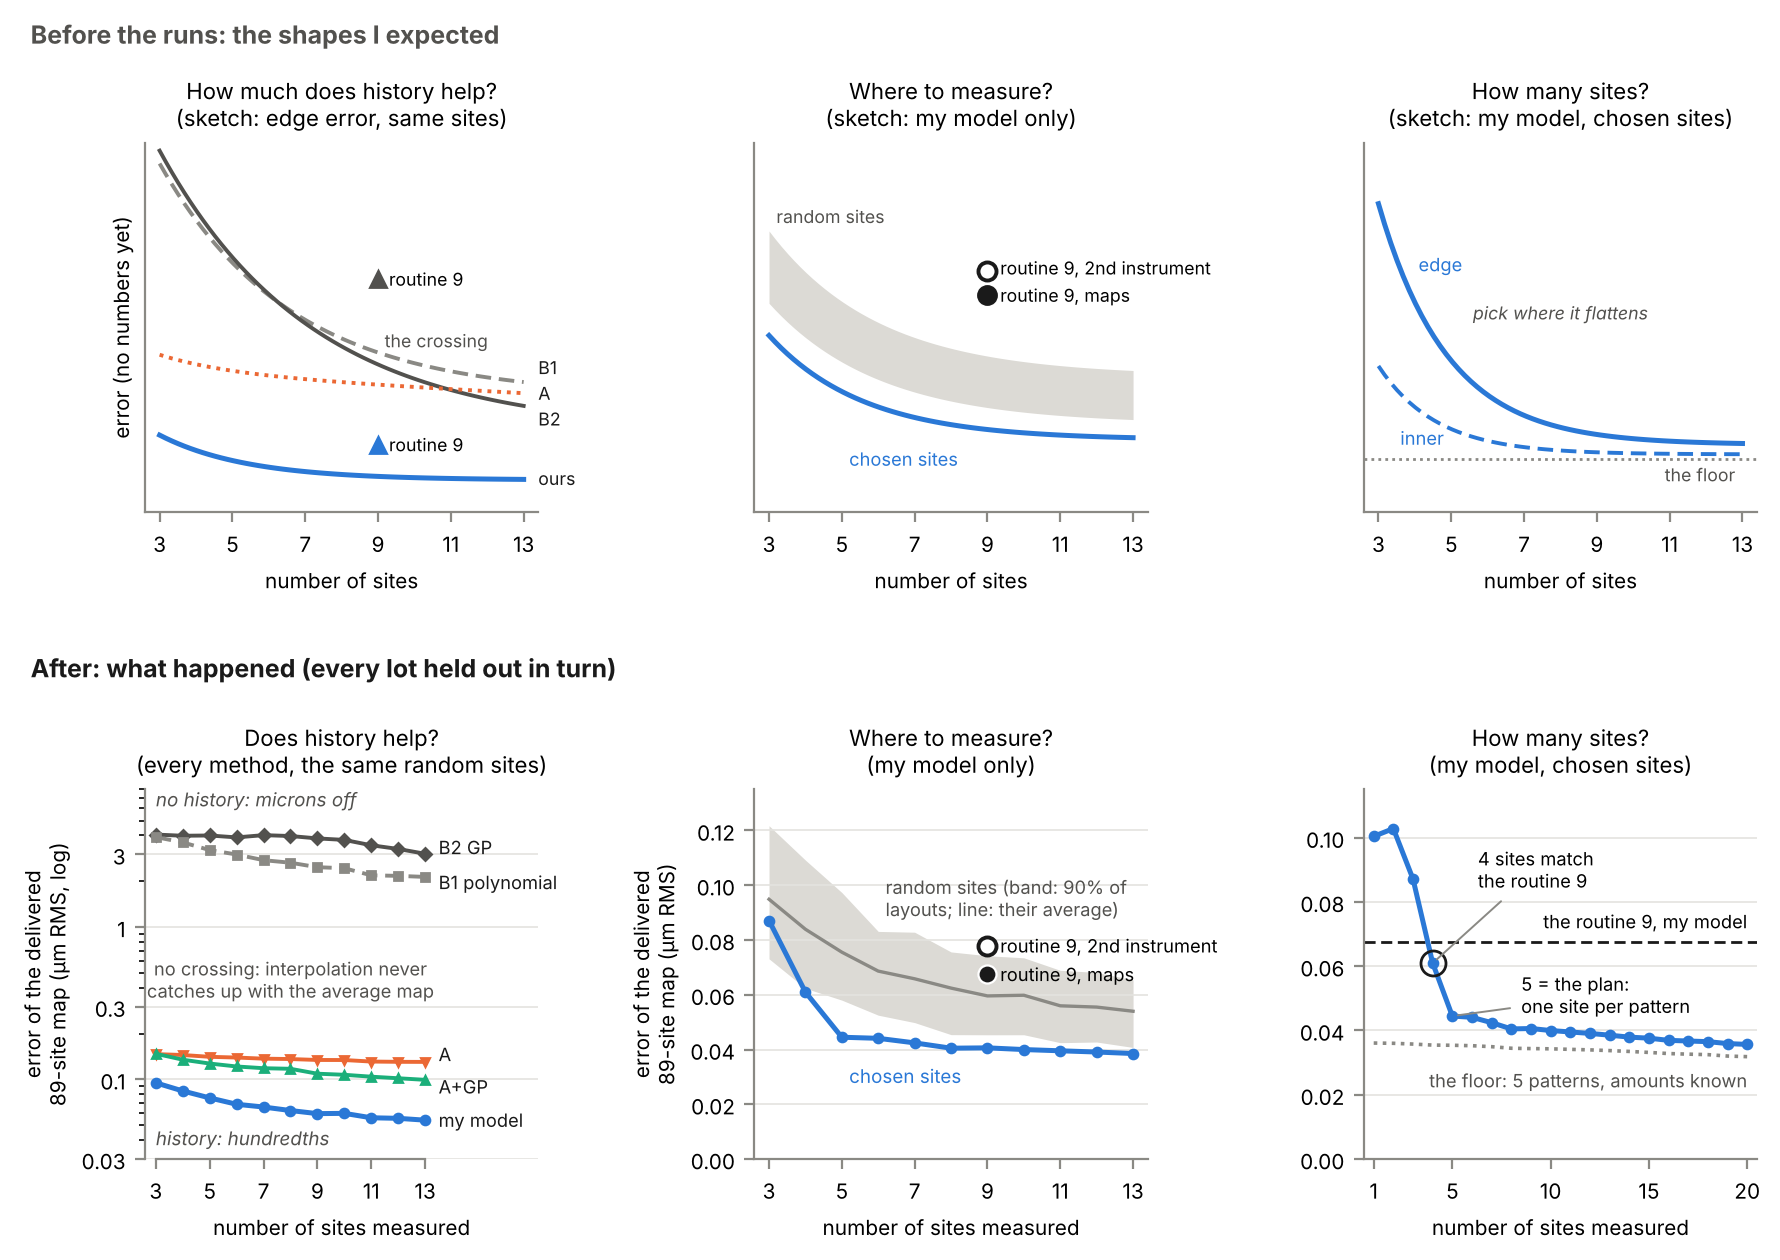

In [19]:
LS = {'B1': (0, (4, 2)), 'B2': '-', 'A': '-', 'A+GP': '-', 'ours': '-'}
MK = {'B1': 's', 'B2': 'D', 'A': 'v', 'A+GP': '^', 'ours': 'o'}
SHORT = {'B1': 'B1 polynomial', 'B2': 'B2 GP', 'A': 'A', 'A+GP': 'A+GP', 'ours': 'my model'}
def tidy(ax, ygrid=True):
    ax.spines[['top', 'right']].set_visible(False)
    for s in ['left', 'bottom']:
        ax.spines[s].set_color(INK3)
    ax.tick_params(labelsize=7.5, color=INK3)
    if ygrid:
        ax.grid(axis='y', color=GRID, lw=0.6)

def panel_history(ax):
    for meth in ['B2', 'B1', 'A', 'A+GP', 'ours']:
        e = [err(('random', k, meth)) for k in KR]
        ax.plot(KR, e, ls=LS[meth], marker=MK[meth], ms=3.2, lw=1.8 if meth == 'ours' else 1.4, color=COL[meth])
        ax.text(13.5, e[-1] * {'B2': 1.1, 'B1': 0.92, 'A': 1.12, 'A+GP': 0.9, 'ours': 1.0}[meth], SHORT[meth],
                fontsize=6.6, va='center', color=INK)
    ax.set_yscale('log')
    ax.set_ylim(0.03, 8)
    ax.set_yticks([0.03, 0.1, 0.3, 1, 3])
    ax.set_yticklabels(['0.03', '0.1', '0.3', '1', '3'])
    ax.text(3, 6.2, 'no history: microns off', fontsize=6.8, color=INK2, style='italic')
    ax.text(3, 0.037, 'history: hundredths', fontsize=6.8, color=INK2, style='italic')
    ax.text(8, 0.45, 'no crossing: interpolation never\ncatches up with the average map', fontsize=6.6, color=INK2, ha='center', va='center')
    ax.set_ylabel('error of the delivered\n89-site map (µm RMS, log)', fontsize=7.5)
    ax.set_title('Does history help?\n(every method, the same random sites)', fontsize=8)

def panel_where(ax):
    per = np.array([[err(('random', k, 'ours'), layout=j) for j in range(NR)] for k in KR])
    q5, q95 = np.quantile(per, 0.05, axis=1), np.quantile(per, 0.95, axis=1)
    ax.fill_between(KR, q5, q95, color='#dcdad5', lw=0)
    ax.plot(KR, [err(('random', k, 'ours')) for k in KR], color=INK3, lw=1.2)
    ax.plot(KR, [err(('chosen', k, 'ours')) for k in KR], '-o', ms=3.2, lw=1.8, color=COL['ours'])
    ax.plot(9, err(('routine', 9, 'ours')), 'o', ms=6.5, color=INK, mec='white', mew=0.8, zorder=4)
    ax.plot(9, err(('instrument', 9, 'ours')), 'o', ms=6.5, mfc='white', mec=INK, mew=1.4, zorder=4)
    ax.text(9.35, err(('routine', 9, 'ours')), 'routine 9, maps', fontsize=6.6, va='center')
    ax.text(9.35, err(('instrument', 9, 'ours')), 'routine 9, 2nd instrument', fontsize=6.6, va='center')
    ax.text(6.2, q95[3] + 0.004, 'random sites (band: 90% of\nlayouts; line: their average)', fontsize=6.6, color=INK2, va='bottom')
    ax.text(5.2, err(('chosen', 5, 'ours')) - 0.010, 'chosen sites', fontsize=6.8, color=COL['ours'], va='top')
    ax.set_ylim(0, 0.135)
    ax.set_ylabel('error of the delivered\n89-site map (µm RMS)', fontsize=7.5)
    ax.set_title('Where to measure?\n(my model only)', fontsize=8)

def panel_howmany(ax):
    e = [err(('chosen', k, 'ours')) for k in KC]
    fl = [err(('floor', k, 'ours')) for k in KC]
    r9 = err(('routine', 9, 'ours'))
    ax.axhline(r9, color=INK, lw=1.0, ls=(0, (4, 2)))
    ax.text(20, r9 + 0.003, 'the routine 9, my model', fontsize=6.6, ha='right', va='bottom')
    ax.plot(KC, fl, color=INK3, lw=1.3, ls=(0, (1, 1.5)))
    ax.text(20, fl[-1] - 0.004, 'the floor: 5 patterns, amounts known', fontsize=6.6, ha='right', va='top', color=INK2)
    ax.plot(KC, e, '-o', ms=3.2, lw=1.8, color=COL['ours'])
    ax.plot(4, e[3], 'o', ms=9, mfc='none', mec=INK, mew=1.0)
    ax.annotate('4 sites match\nthe routine 9', xy=(4, e[3]), xytext=(6.3, 0.090), fontsize=6.6, va='center',
                arrowprops=dict(arrowstyle='-', color=INK3, lw=0.7))
    ax.annotate('5 = the plan:\none site per pattern', xy=(5, e[4]), xytext=(8.5, 0.051), fontsize=6.6, va='center',
                arrowprops=dict(arrowstyle='-', color=INK3, lw=0.7))
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_xlim(0.5, 20.5)
    ax.set_ylim(0, 0.115)
    ax.set_title('How many sites?\n(my model, chosen sites)', fontsize=8)

def results(axes):
    panel_history(axes[0]); panel_where(axes[1]); panel_howmany(axes[2])
    for ax in axes:
        tidy(ax)
        ax.set_xlabel('number of sites measured', fontsize=7.5)
    for ax in axes[:2]:
        ax.set_xticks([3, 5, 7, 9, 11, 13])
        ax.set_xlim(2.6, 13.4)
    axes[0].set_xlim(2.6, 17.2)
    axes[0].spines['bottom'].set_bounds(3, 13)

def sketch(axes):
    """The curves sketched in the project plan before any run: shapes only, no numbers."""
    x = np.linspace(3, 13, 60)
    a = axes[0]
    a.plot(x, 0.72 + 1.45 * np.exp(-(x - 3) / 3.6), color=COL['B1'], ls=LS['B1'], lw=1.4)
    a.plot(x, 0.50 + 1.75 * np.exp(-(x - 3) / 4.2), color=COL['B2'], lw=1.4)
    a.plot(x, 0.98 - 0.012 * (x - 3) - 0.12 * (1 - np.exp(-(x - 3) / 2)), color=COL['A'], lw=1.4, ls=(0, (1, 1.5)))
    a.plot(x, 0.20 + 0.28 * np.exp(-(x - 3) / 2.4), color=COL['ours'], lw=1.8)
    a.plot(9, 1.45, '^', ms=6, color=COL['B2'])
    a.plot(9, 0.42, '^', ms=6, color=COL['ours'])
    a.text(9.3, 1.45, 'routine 9', fontsize=6.4, va='center')
    a.text(9.3, 0.42, 'routine 9', fontsize=6.4, va='center')
    a.text(10.6, 1.0, 'the crossing', fontsize=6.4, color=INK2, ha='center', va='bottom')
    for t_, yy in [('B1', 0.90), ('B2', 0.58), ('A', 0.74), ('ours', 0.21)]:
        a.text(13.4, yy, t_, fontsize=6.4, va='center', color=INK)
    a.set_title('How much does history help?\n(sketch: edge error, same sites)', fontsize=8)
    b = axes[1]
    b.fill_between(x, 0.55 + 0.75 * np.exp(-(x - 3) / 3), 0.85 + 0.9 * np.exp(-(x - 3) / 3), color='#dcdad5', lw=0)
    b.plot(x, 0.45 + 0.65 * np.exp(-(x - 3) / 2.6), color=COL['ours'], lw=1.8)
    b.plot(9, 1.35, 'o', ms=6.5, color=INK)
    b.plot(9, 1.5, 'o', ms=6.5, mfc='white', mec=INK, mew=1.4)
    b.text(9.35, 1.35, 'routine 9, maps', fontsize=6.4, va='center')
    b.text(9.35, 1.52, 'routine 9, 2nd instrument', fontsize=6.4, va='center')
    b.text(3.2, 1.8, 'random sites', fontsize=6.4, color=INK2)
    b.text(5.2, 0.40, 'chosen sites', fontsize=6.6, color=COL['ours'], va='top')
    b.set_title('Where to measure?\n(sketch: my model only)', fontsize=8)
    c = axes[2]
    c.plot(x, 0.42 + 1.5 * np.exp(-(x - 3) / 1.9), color=COL['ours'], lw=1.8)
    c.plot(x, 0.36 + 0.55 * np.exp(-(x - 3) / 1.6), color=COL['ours'], lw=1.4, ls=(0, (4, 2)))
    c.axhline(0.33, color=INK3, lw=1.0, ls=(0, (1, 1.5)))
    c.text(12.8, 0.30, 'the floor', fontsize=6.4, ha='right', va='top', color=INK2)
    c.text(4.1, 1.5, 'edge', fontsize=6.6, color=COL['ours'])
    c.text(3.6, 0.42, 'inner', fontsize=6.6, color=COL['ours'])
    c.text(8, 1.2, 'pick where it flattens', fontsize=6.4, color=INK2, ha='center', style='italic')
    c.set_title('How many sites?\n(sketch: my model, chosen sites)', fontsize=8)
    for ax in axes:
        tidy(ax, ygrid=False)
        ax.set_yticks([])
        ax.set_ylim(0, 2.3)
        ax.set_xticks([3, 5, 7, 9, 11, 13])
        ax.set_xlim(2.6, 13.4)
        ax.set_xlabel('number of sites', fontsize=7.5)
    axes[0].set_ylabel('error (no numbers yet)', fontsize=7.5)

fig, axes = plt.subplots(2, 3, figsize=(10.4, 6.6), gridspec_kw=dict(wspace=0.55, hspace=0.75))
sketch(axes[0])
results(axes[1])
fig.text(0.07, 0.955, 'Before the runs: the shapes I expected', fontsize=9, fontweight='bold', color=INK2)
fig.text(0.07, 0.475, 'After: what happened (every lot held out in turn)', fontsize=9, fontweight='bold', color=INK)
fig.savefig(os.path.join(FIG_DIR, 'part5_sketch_vs_result.png'), dpi=220, bbox_inches='tight')
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.1), gridspec_kw=dict(wspace=0.55))    # the result row alone
results(axes)
fig.savefig(os.path.join(FIG_DIR, 'part5_three_questions.png'), dpi=220, bbox_inches='tight')
plt.close(fig)

In [20]:
per = {k: np.array([err(('random', k, 'ours'), layout=j) for j in range(NR)]) for k in KR}
print('Chosen sites against the 200 random layouts (whole map):')
for k in [3, 4, 5, 9, 13]:
    print('  %2d sites: chosen %.3f | random: middle 90%% %.3f-%.3f, average %.3f | chosen beats %d of 200'
          % (k, err(('chosen', k, 'ours')), *np.quantile(per[k], [0.05, 0.95]), err(('random', k, 'ours')),
             (err(('chosen', k, 'ours')) < per[k]).sum()))
for part in ['inner', 'edge', None]:
    pr = np.array([err(('random', 9, 'ours'), part, j) for j in range(NR)])
    print('routine 9, %-10s %.3f µm: worse than %d%% of random 9-site layouts'
          % (part or 'whole map:', err(('routine', 9, 'ours'), part), 100 * (pr < err(('routine', 9, 'ours'), part)).mean()))
print('Lots (of 10) where chosen sites beat the routine 9: 4 sites %d, 5 sites %d'
      % ((per_lot(('chosen', 4, 'ours')) < per_lot(('routine', 9, 'ours'))).sum(),
         (per_lot(('chosen', 5, 'ours')) < per_lot(('routine', 9, 'ours'))).sum()))
print('Chosen sites against the floor (whole / inner / edge):')
for k in [3, 4, 5, 7, 13, 20]:
    print('  %2d sites: %.3f / %.3f / %.3f   floor %.3f / %.3f / %.3f' % (k, *[err(('chosen', k, 'ours'), p) for p in [None, 'inner', 'edge']],
                                                                    *[err(('floor', k, 'ours'), p) for p in [None, 'inner', 'edge']]))
print('Rival A from 3 to 13 random sites: %.3f -> %.3f | rival B1 at 13 sites: %.2f, %.0f times rival A'
      % (err(('random', 3, 'A')), err(('random', 13, 'A')), err(('random', 13, 'B1')), err(('random', 13, 'B1')) / err(('random', 13, 'A'))))

Chosen sites against the 200 random layouts (whole map):
   3 sites: chosen 0.087 | random: middle 90% 0.073-0.122, average 0.095 | chosen beats 119 of 200
   4 sites: chosen 0.061 | random: middle 90% 0.062-0.109, average 0.084 | chosen beats 195 of 200
   5 sites: chosen 0.044 | random: middle 90% 0.058-0.097, average 0.076 | chosen beats 200 of 200
   9 sites: chosen 0.041 | random: middle 90% 0.045-0.074, average 0.060 | chosen beats 199 of 200
  13 sites: chosen 0.039 | random: middle 90% 0.041-0.065, average 0.054 | chosen beats 198 of 200
routine 9, inner      0.016 µm: worse than 0% of random 9-site layouts
routine 9, edge       0.099 µm: worse than 85% of random 9-site layouts
routine 9, whole map: 0.067 µm: worse than 83% of random 9-site layouts
Lots (of 10) where chosen sites beat the routine 9: 4 sites 7, 5 sites 10
Chosen sites against the floor (whole / inner / edge):
   3 sites: 0.087 / 0.056 / 0.114   floor 0.036 / 0.021 / 0.048
   4 sites: 0.061 / 0.054 / 0.069   floo

**What matched the sketch.**
- My model is lowest at every count, and rival A barely improves with more sites (0.146 µm at 3 random
  sites, 0.130 at 13): more readings only refine its level.
- Chosen sites sit below the band of random layouts from 4 sites on. At 5 sites they beat all 200 random
  layouts; at 9 and 13, all but one and two.
- The second instrument is a little worse than reading the routine 9 off the maps.
- The error falls, then flattens toward a floor.

**What did not.**
1. **No crossing.** I expected interpolation to overtake the average map once random sites reach the
   edge. At 13 sites the polynomial is still 16 times worse than rival A (2.13 against 0.130 µm), and
   part 4's budget plot shows a Gaussian process needs about 82 of the 89 sites to match my model's 5.
   Nothing in a wafer's own readings says how deep its unmeasured edge is.
2. **The routine 9 is not above the band.** Its inner sites are excellent (0.016 µm, better than every
   random 9-site layout), which offsets its blind edge (0.099 µm, worse than 85% of random layouts). On
   the whole map it is worse than 83% of random layouts, inside the band.
3. **The edge does not flatten later than the inside.** Both flatten at 5 sites, one per pattern. With
   fewer sites than patterns, some pattern amounts are guessed from the prior, and even chosen sites
   barely beat random ones (3 chosen sites beat 119 of 200 random layouts). From 5 sites on, what is left is
   mostly what the patterns cannot describe: 5 chosen sites are 0.009 µm above the floor, 20 sites 0.004.
4. **"Pick where it flattens" was replaced** by a rule decided on training lots (part 4): the fewest
   chosen sites no worse than the routine 9 (4 sites, which match it here and beat it in 7 lots of 10),
   and never fewer sites than patterns (5, which beat it in all 10 lots). The curve shows why the two
   agree: the flattening starts at 5.

## 6. The whole project, one idea per step
Each row adds one idea. Rows 1 to 5 are the routine 9 with more and more history; row 6 moves the
sites; row 7 is the floor. Open dots: the inner 49 sites; filled: the edge 40.

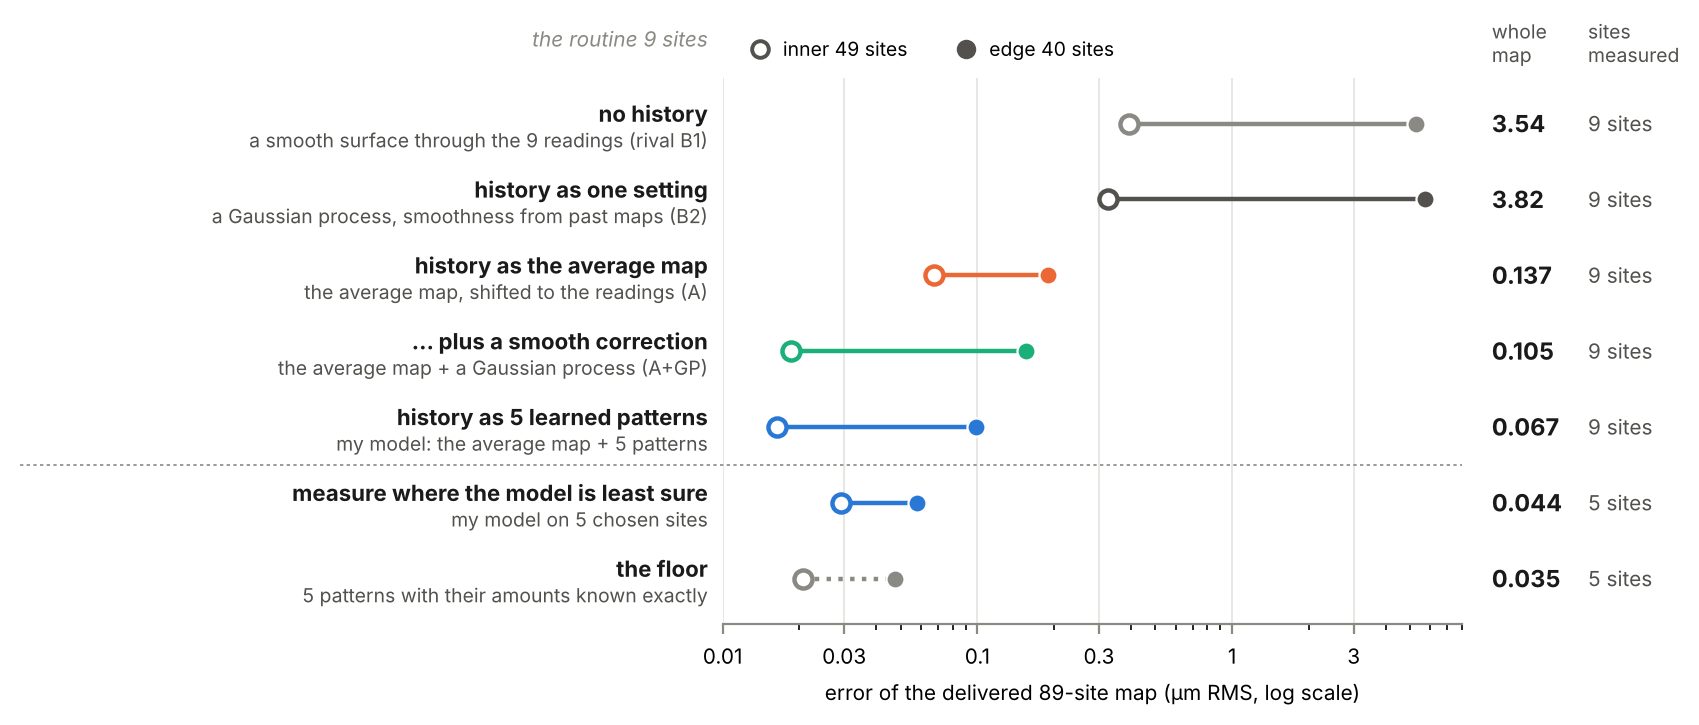

In [21]:
STEPS = [('no history', 'a smooth surface through the 9 readings (rival B1)', ('routine', 9, 'B1'), 'B1', '9'),
         ('history as one setting', 'a Gaussian process, smoothness from past maps (B2)', ('routine', 9, 'B2'), 'B2', '9'),
         ('history as the average map', 'the average map, shifted to the readings (A)', ('routine', 9, 'A'), 'A', '9'),
         ('... plus a smooth correction', 'the average map + a Gaussian process (A+GP)', ('routine', 9, 'A+GP'), 'A+GP', '9'),
         ('history as 5 learned patterns', 'my model: the average map + 5 patterns', ('routine', 9, 'ours'), 'ours', '9'),
         ('measure where the model is least sure', 'my model on 5 chosen sites', ('chosen', 5, 'ours'), 'ours', '5'),
         ('the floor', '5 patterns with their amounts known exactly', ('floor', 5, 'ours'), 'floor', '5')]
fig = plt.figure(figsize=(8.6, 3.9))
ax = fig.add_axes([0.40, 0.13, 0.43, 0.70])
n = len(STEPS)
for i, (head, sub, key, meth, k) in enumerate(STEPS):
    yv = n - 1 - i
    col = COL.get(meth, INK3)
    ei, ee, ew = err(key, 'inner'), err(key, 'edge'), err(key)
    if i == 5:
        ax.axhline(yv + 0.5, color=INK3, lw=0.6, ls=(0, (2, 2)), xmin=-0.95, clip_on=False)
    ax.plot([ei, ee], [yv, yv], color=col, lw=1.6, solid_capstyle='round', zorder=2, ls=':' if meth == 'floor' else '-')
    ax.plot(ei, yv, 'o', ms=6.5, mfc='white', mec=col, mew=1.6, zorder=3)
    ax.plot(ee, yv, 'o', ms=6.5, color=col, mec='white', mew=0.8, zorder=3)
    ax.text(-0.02, yv + 0.13, head, transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=8, color=INK, fontweight='bold')
    ax.text(-0.02, yv - 0.22, sub, transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=7, color=INK2)
    ax.text(1.04, yv, ('%.2f' if ew >= 1 else '%.3f') % ew, transform=ax.get_yaxis_transform(), ha='left', va='center',
            fontsize=8.5, color=INK, fontweight='bold')
    ax.text(1.17, yv, k + ' sites', transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=7.5, color=INK2)
ax.text(1.04, n - 0.25, 'whole\nmap', transform=ax.get_yaxis_transform(), ha='left', va='bottom', fontsize=7, color=INK2)
ax.text(1.17, n - 0.25, 'sites\nmeasured', transform=ax.get_yaxis_transform(), ha='left', va='bottom', fontsize=7, color=INK2)
ax.text(-0.02, n - 0.05, 'the routine 9 sites', transform=ax.get_yaxis_transform(), ha='right', va='bottom', fontsize=7.5, color=INK3, style='italic')
ax.set_xscale('log')
ax.set_xlim(0.012, 8)
ax.set_ylim(-0.6, n - 0.4)
ax.set_yticks([])
ax.set_xticks([0.01, 0.03, 0.1, 0.3, 1, 3])
ax.set_xticklabels(['0.01', '0.03', '0.1', '0.3', '1', '3'])
ax.set_xlabel('error of the delivered 89-site map (µm RMS, log scale)', fontsize=7.5)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color(INK3)
ax.tick_params(labelsize=7.5, color=INK3)
ax.grid(axis='x', color=GRID, lw=0.6)
ax.plot([], [], 'o', ms=6, mfc='white', mec=INK2, mew=1.4, label='inner 49 sites')
ax.plot([], [], 'o', ms=6, color=INK2, label='edge 40 sites')
ax.legend(fontsize=7, frameon=False, ncol=2, loc='lower left', bbox_to_anchor=(0.0, 1.0), handletextpad=0.2)
fig.savefig(os.path.join(FIG_DIR, 'part5_ladder.png'), dpi=220, bbox_inches='tight')
plt.show()

**Reading the ladder.** Without history, the routine 9 gets the inside right to 0.39 µm but misses the
edge by 5.3 µm: it never measures there, and nothing in its readings says how deep the edge is. A
smoothness learned from past maps does not help. The average past map does: it knows the edge is
deeper, and the error falls to 0.137 µm. Five learned patterns, which know *how* wafers differ from the
average, bring it to 0.067. Then moving the sites: 5 chosen sites instead of the routine 9 give 0.044,
0.009 µm above the floor. They trade a little accuracy inside (0.016 → 0.029 µm) for a much better edge
(0.099 → 0.058). The full map, 89 sites, has no error at all; the plan's question is how close to it a few
sites can get.

## 7. The answers, on one page
The numbers for the plan as deployed are this run's (leave-one-lot-out, with the flag). Two answers
come from notebook 04, which ran them: learning from earlier lots only (its section 5) and the budget
(its section 8). They are copied here as printed there.

In [22]:
pl = PLAN[PLAN.layout == 'plan']
passed = pl[pl.flagged == 0]
print('The plan as deployed, every lot held out in turn: %.2f sites on average, %.1f%% of wafers flagged %s,'
      % (pl.k.mean(), 100 * pl.flagged.mean(), pl[pl.flagged == 1].groupby('lot').size().to_dict()))
print('  on wafers the flag passes: error %.3f µm, 90%% ranges hold %.1f%%' % (rms_of(passed), 100 * coverage_of(passed)))
print('  delivered map, flagged wafers measured in full: %.3f µm, %.1f sites per wafer'
      % (map_rms(pl), (pl.k + pl.remeasured + pl.flagged * (89 - pl.k)).mean()))
FROM_NB04 = dict(plan_earlier_lots=0.045, routine9_earlier_lots=0.067, ratio_to_lolo=1.10, coverage_earlier_lots=0.92,
                 gp_alone_sites_to_match=82, avg_map_gp_sites_to_match=43, full_maps=79, break_even_wafers=91)
print('From notebook 04:', FROM_NB04)

The plan as deployed, every lot held out in turn: 5.11 sites on average, 12.5% of wafers flagged {1: 9, 8: 2},
  on wafers the flag passes: error 0.041 µm, 90% ranges hold 92.4%
  delivered map, flagged wafers measured in full: 0.037 µm, 15.7 sites per wafer
From notebook 04: {'plan_earlier_lots': 0.045, 'routine9_earlier_lots': 0.067, 'ratio_to_lolo': 1.1, 'coverage_earlier_lots': 0.92, 'gp_alone_sites_to_match': 82, 'avg_map_gp_sites_to_match': 43, 'full_maps': 79, 'break_even_wafers': 91}


Error is that of the delivered 89-site map, in µm, every lot held out in turn unless stated.

| Question | Answer | The numbers |
|---|---|---|
| Why not just interpolate each wafer's own readings? | Nothing in a wafer's own readings says how deep its edge is. | From the routine 9, a smooth surface gets the inside to 0.39 but misses the edge by 5.3. |
| Does history help? | Yes, by a factor of 40 to 50. | Same 5 random sites: my model 0.076, polynomial 3.20, Gaussian process 3.99. Better in 10 of 10 lots. |
| Which kind of history? | Patterns learned from past wafers, not only their average. | Same 5 random sites: 0.076, against 0.141 for the average map and 0.127 for the average map + GP. 10 of 10 lots. |
| Is the gain from the patterns or from where we measure? | The patterns. My sites help only a model that knows them. | On my 5 chosen sites: my model 0.044, the GP 5.00 (3.99 on random sites), the average map + GP 0.206 (0.127). |
| Where to measure? | Where the model is least sure, mostly at the edge. | 5 chosen sites beat all 200 random 5-site layouts, and the routine 9 in 10 of 10 lots (0.044 against 0.067). |
| How many sites? | 5: one per pattern. | 4 chosen sites already match the routine 9 (0.061 against 0.067). From 5 on, the error sits just above the floor (0.044 against 0.035). |
| Can one wafer's map be trusted? | On wafers like the past, yes. The flag catches the others. | The 90% ranges hold 92% on wafers the flag passes. The flag sends all 9 wafers of the unusual lot 1 (and 2 of lot 8) for a full map. |
| Does it hold forward in time? | Yes. | Learned from earlier lots only: 0.045 from 5 sites, against 0.067 from the routine 9, within ×1.10 of leave-one-lot-out (notebook 04). |
| Does it work with the fab's own instrument? | Yes; the order of the methods holds. | Routine 9 read by the second instrument: my model 0.078, average map + GP 0.114, average map 0.146, polynomial 3.55. |
| Is the history worth its full maps? | Yes, after about 90 wafers. | Without history, a GP needs about 82 sites per wafer to match my model's 5, so the 79 full maps pay back after about 91 wafers (notebook 04). |

## 8. Why earlier notebooks show different numbers for the same box
Each part changed something: the model, what happens to a reading the check questions, or the score.
The same box therefore reads differently from notebook to notebook. Each number was right for its own
question; this notebook's are the ones to use when comparing methods or sites.

| Notebook | Model | A reading the check questions | Score | My model, 5 random sites | 5 chosen sites | The routine 9 |
|---|---|---|---|---|---|---|
| 01 | 4 patterns, separate priors | no check yet | unmeasured sites, inner / edge | 0.043 / 0.116 | – | 0.021 / 0.109 |
| 02 | same | dropped | unmeasured sites, inner / edge | 0.053 / 0.126 | – | 0.021 / 0.109 |
| 03 | final: 5 patterns, joint prior | dropped | unmeasured sites, inner / edge | 0.045 / 0.115 | 0.053 / 0.090 | 0.018 / 0.099 |
| 04 | final | re-measured, kept unless suspect | sites both layouts leave unmeasured | – | 0.047 (routine 9: 0.066) | – |
| 05 | final, chosen per fold | re-measured, kept unless suspect | delivered map: whole (inner / edge) | 0.076 (0.037 / 0.105) | 0.044 (0.029 / 0.058) | 0.067 (0.016 / 0.099) |

Three things move the numbers:
- **The score.** The delivered map counts the measured sites, which have no error, so its inner and edge
  numbers are lower than errors at unmeasured sites only. Its whole-map number is a different average
  again, over all 89 sites.
- **The input policy.** Notebooks 02 and 03 dropped every questioned reading. On lot 1 the check
  questions most chosen-site wafers, and dropping a good reading cost those wafers dearly. Scored as in
  notebook 03 (unmeasured sites only) but with re-measuring, 5 chosen sites give 0.030 / 0.061 instead
  of 0.053 / 0.090 (printed below): the policy, not the score, made that difference.
- **The flag.** Notebook 04's plan sends flagged wafers for a full map, so its delivered map error
  (0.037 here, every lot held out in turn) is lower than this notebook's 0.044, which scores every wafer
  by its 5-site map so that methods compare on equal terms. Use notebook 04's numbers for the plan as
  deployed, and this notebook's for comparing methods and sites.

In [23]:
c5 = PLAN[PLAN.layout == 'chosen 5']
print('5 chosen sites, error at unmeasured sites only (notebook 03\'s score), questioned readings re-measured:')
print('  inner %.3f / edge %.3f µm (notebook 03, questioned readings dropped: 0.053 / 0.090)' % (rms_of(c5, inner), rms_of(c5, ~inner)))
print('  lot 1: %.3f / %.3f | lots 2-10: %.3f / %.3f' % (rms_of(c5[c5.lot == 1], inner), rms_of(c5[c5.lot == 1], ~inner),
                                                       rms_of(c5[c5.lot > 1], inner), rms_of(c5[c5.lot > 1], ~inner)))

5 chosen sites, error at unmeasured sites only (notebook 03's score), questioned readings re-measured:
  inner 0.030 / edge 0.061 µm (notebook 03, questioned readings dropped: 0.053 / 0.090)
  lot 1: 0.049 / 0.082 | lots 2-10: 0.026 / 0.058


## 9. Summary of part 5
- **History is the whole difference at the edge.** On the same sites, the methods without history miss
  the 89-site map by microns and those with history by hundredths. The interpolation rivals never catch
  up as sites are added. Learned patterns beat the average map alone by a factor of about 2.
- **The gain comes from the patterns, not just the sites.** My model's chosen sites make the Gaussian
  processes worse; each method on its own best sites gains little or nothing.
- **Where and how many:** 5 sites chosen by the model, one per pattern, beat every random 5-site layout
  and the routine 9 in all 10 lots (0.044 against 0.067 µm), within 0.009 µm of the floor.
- **Against the sketch:** the expected shapes held, except that interpolation never crossed the
  average map, the routine 9 sat inside the random band (excellent inside, blind at the edge), and the
  edge flattened at the same count as the inside: one site per pattern.